In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../data/yelp_sample_1000.csv")

print("Dataset Shape:", df.shape)
print(df["stars"].value_counts().sort_index())

Dataset Shape: (1000, 3)
stars
1    200
2    200
3    200
4    200
5    200
Name: count, dtype: int64


In [2]:
from sklearn.model_selection import train_test_split

_, eval_df = train_test_split(
    df,
    test_size=0.20,
    stratify=df["stars"],
    random_state=42
)

print("Evaluation Shape:", eval_df.shape)
print(eval_df["stars"].value_counts().sort_index())

Evaluation Shape: (200, 3)
stars
1    40
2    40
3    40
4    40
5    40
Name: count, dtype: int64


In [3]:
from pathlib import Path

output_path = Path("../data/eval_indices.csv")

eval_indices = pd.DataFrame({
    "original_index": eval_df.index
})

eval_indices.to_csv(output_path, index=False)

print("Kaydedilen örnek sayısı:", len(eval_indices))
print("Dosya:", output_path)

Kaydedilen örnek sayısı: 200
Dosya: ../data/eval_indices.csv


In [4]:
from transformers import pipeline

MODEL_NAME = "nlptown/bert-base-multilingual-uncased-sentiment"

classifier = pipeline(
    "text-classification",
    model=MODEL_NAME
)

print(classifier.model.config.id2label)

/home/pasali/anaconda3/envs/myenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3059.76it/s]


{0: '1 star', 1: '2 stars', 2: '3 stars', 3: '4 stars', 4: '5 stars'}


In [5]:
def model_label_to_stars(label):
    label_mapping = {
        "1 star": 1,
        "2 stars": 2,
        "3 stars": 3,
        "4 stars": 4,
        "5 stars": 5
    }

    if label not in label_mapping:
        raise ValueError(f"Geçersiz etiket: {label}")

    return label_mapping[label]

In [6]:
print(model_label_to_stars("1 star"))
print(model_label_to_stars("3 stars"))
print(model_label_to_stars("5 stars"))

1
3
5


In [7]:
text = "The food was terrible and the service was extremely slow."

prediction = classifier(
    text,
    truncation=True,
    max_length=256
)

print(prediction)

[{'label': '1 star', 'score': 0.6184412837028503}]


In [8]:
texts = eval_df["text"].tolist()

predictions = classifier(
    texts,
    truncation=True,
    max_length=256,
    batch_size=8
)

print("Number of Predictions:", len(predictions))
print("First Prediction:", predictions[0])

Number of Predictions: 200
First Prediction: {'label': '2 stars', 'score': 0.6330277919769287}


In [9]:
y_pred = np.array([
    model_label_to_stars(pred["label"])
    for pred in predictions
])

y_true = eval_df["stars"].to_numpy()

print("y_true shape:", y_true.shape)
print("y_pred shape:", y_pred.shape)

print("İlk 5 gerçek yıldız:", y_true[:5])
print("İlk 5 tahmin:", y_pred[:5])

y_true shape: (200,)
y_pred shape: (200,)
İlk 5 gerçek yıldız: [3 1 2 2 4]
İlk 5 tahmin: [2 1 2 2 5]


In [10]:
print("Tahmin sayısı:", len(predictions))
print("Gerçek etiket sayısı:", len(y_true))
print("Tahmin etiketleri:", np.unique(y_pred))
print("Gerçek etiketler:", np.unique(y_true))

assert len(predictions) == len(eval_df) == 200
assert y_true.shape == (200,)
assert y_pred.shape == (200,)
assert np.isin(y_pred, [1, 2, 3, 4, 5]).all()
assert np.isin(y_true, [1, 2, 3, 4, 5]).all()

print("Kontroller: PASSED")

Tahmin sayısı: 200
Gerçek etiket sayısı: 200
Tahmin etiketleri: [1 2 3 4 5]
Gerçek etiketler: [1 2 3 4 5]
Kontroller: PASSED


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

accuracy = accuracy_score(y_true, y_pred)

macro_precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)

macro_recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)

macro_f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

results_df = pd.DataFrame({
    "Metric": [
        "Evaluation Samples",
        "Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro-F1"
    ],
    "Result": [
        len(y_true),
        accuracy,
        macro_precision,
        macro_recall,
        macro_f1
    ]
})

display(results_df)

,Metric,Result
0,Evaluation Samples,200.000000
1,Accuracy,0.555000
2,Macro Precision,0.560473
3,Macro Recall,0.555000
4,Macro-F1,0.553163


In [12]:
print(classification_report(
    y_true,
    y_pred,
    labels=[1, 2, 3, 4, 5],
    target_names=["1 Star", "2 Stars", "3 Stars", "4 Stars", "5 Stars"],
    zero_division=0
))

              precision    recall  f1-score   support

      1 Star       0.75      0.60      0.67        40
     2 Stars       0.54      0.55      0.54        40
     3 Stars       0.47      0.38      0.42        40
     4 Stars       0.43      0.50      0.47        40
     5 Stars       0.61      0.75      0.67        40

    accuracy                           0.56       200
   macro avg       0.56      0.55      0.55       200
weighted avg       0.56      0.56      0.55       200



In [13]:
one_star_mask = (y_true == 1)

one_star_true = y_true[one_star_mask]
one_star_pred = y_pred[one_star_mask]

print("Gerçek 1 yıldızlı yorum:", len(one_star_true))
print("Gerçek etiketler:", np.unique(one_star_true))
print("Model tahminleri:", one_star_pred)

Gerçek 1 yıldızlı yorum: 40
Gerçek etiketler: [1]
Model tahminleri: [1 2 1 2 2 2 1 1 1 1 2 1 1 1 1 1 2 2 1 1 1 1 2 4 2 1 1 1 1 1 2 3 1 2 1 2 1
 1 2 2]


In [14]:
correct_predictions = np.sum(one_star_pred == 1)
incorrect_predictions = np.sum(one_star_pred != 1)

print("Doğru tahmin:", correct_predictions)
print("Yanlış tahmin:", incorrect_predictions)
print("Toplam:", correct_predictions + incorrect_predictions)

Doğru tahmin: 24
Yanlış tahmin: 16
Toplam: 40


In [15]:
one_star_recall = correct_predictions / len(one_star_true)

one_star_error_rate = incorrect_predictions / len(one_star_true)

print("1-Star Recall:", one_star_recall)
print("1-Star Error Rate:", one_star_error_rate)

assert np.isclose(one_star_error_rate, 1 - one_star_recall)

print("Kontrol: PASSED")

1-Star Recall: 0.6
1-Star Error Rate: 0.4
Kontrol: PASSED


In [16]:
from sklearn.metrics import confusion_matrix

star_labels = [1, 2, 3, 4, 5]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=star_labels
)

print("Matrix Shape:", cm.shape)
print("Total Samples:", cm.sum())
print(cm)

Matrix Shape: (5, 5)
Total Samples: 200
[[24 14  1  1  0]
 [ 6 22 10  1  1]
 [ 2  4 15 14  5]
 [ 0  1  6 20 13]
 [ 0  0  0 10 30]]


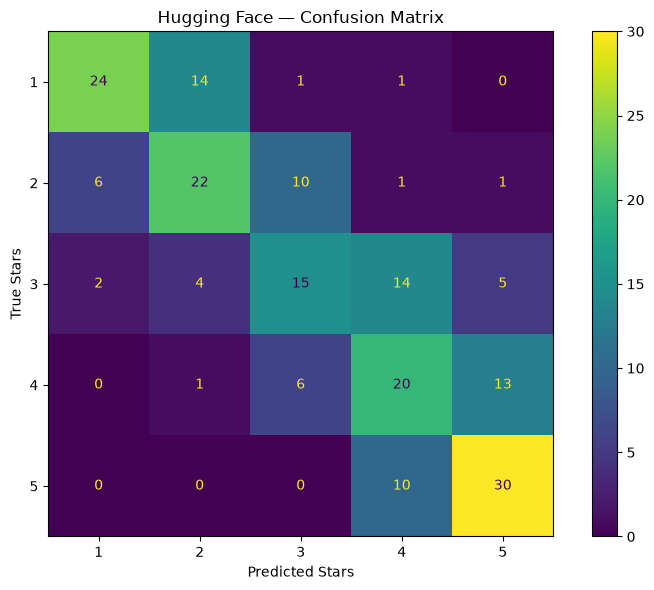

In [17]:
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(8, 6))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=star_labels
)

disp.plot(ax=ax, values_format="d")

ax.set_title("Hugging Face — Confusion Matrix")
ax.set_xlabel("Predicted Stars")
ax.set_ylabel("True Stars")

plt.tight_layout()

Path("../figures").mkdir(parents=True, exist_ok=True)

plt.savefig(
    "../figures/hf_confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [18]:
error_indices = np.where(y_true != y_pred)[0]

print("Toplam yanlış tahmin:", len(error_indices))
print("İlk 10 hata indeksi:", error_indices[:10])

Toplam yanlış tahmin: 89
İlk 10 hata indeksi: [ 0  4  5  6  7 11 12 14 15 16]


In [19]:
selected_errors = []

for star, count in [(1, 2), (2, 1), (3, 1)]:
    indices = error_indices[y_true[error_indices] == star]
    selected_errors.extend(indices[:count])

last_indices = error_indices[
    np.isin(y_true[error_indices], [4, 5])
]

selected_errors.extend(last_indices[:1])

print("Seçilen hata indeksleri:", selected_errors)

Seçilen hata indeksleri: [np.int64(5), np.int64(12), np.int64(16), np.int64(0), np.int64(4)]


In [20]:
error_df = pd.DataFrame({
    "Row ID": eval_df.index[selected_errors],
    "Gerçek Yıldız": y_true[selected_errors],
    "Tahmin": y_pred[selected_errors],
    "Score": [predictions[i]["score"] for i in selected_errors]
})

display(error_df)


,Row ID,Gerçek Yıldız,Tahmin,Score
0,638,1,2,0.339196
1,599,1,2,0.496093
2,907,2,1,0.476728
3,673,3,2,0.633028
4,776,4,5,0.551618


In [21]:
def test_label_mapping():
    expected = {
        "1 star": 1,
        "2 stars": 2,
        "3 stars": 3,
        "4 stars": 4,
        "5 stars": 5
    }

    for label, stars in expected.items():
        assert model_label_to_stars(label) == stars

    try:
        model_label_to_stars("6 stars")
    except ValueError:
        pass
    else:
        raise AssertionError("Geçersiz etiket kabul edildi.")


def test_prediction_alignment():
    assert len(eval_df) == 200
    assert len(texts) == 200
    assert len(predictions) == 200
    assert len(y_true) == 200
    assert len(y_pred) == 200

    assert np.isin(y_true, [1, 2, 3, 4, 5]).all()
    assert np.isin(y_pred, [1, 2, 3, 4, 5]).all()

    assert texts == eval_df["text"].tolist()
    assert np.array_equal(y_true, eval_df["stars"].to_numpy())

    mapped_predictions = np.array([
        model_label_to_stars(pred["label"])
        for pred in predictions
    ])

    assert np.array_equal(y_pred, mapped_predictions)

    sample_indices = [0, 99, 199]

    sample_predictions = classifier(
        [texts[i] for i in sample_indices],
        truncation=True,
        max_length=256,
        batch_size=8
    )

    for i, prediction in zip(sample_indices, sample_predictions):
        assert prediction["label"] == predictions[i]["label"]
        assert np.isclose(
            prediction["score"],
            predictions[i]["score"],
            atol=1e-4
        )


def test_evaluation_metrics():
    assert cm.shape == (5, 5)
    assert cm.sum() == 200

    expected_cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[1, 2, 3, 4, 5]
    )

    assert np.array_equal(cm, expected_cm)

    mask = y_true == 1

    assert mask.sum() == 40

    recall = np.mean(y_pred[mask] == 1)
    error_rate = np.mean(y_pred[mask] != 1)

    assert np.isclose(recall, one_star_recall)
    assert np.isclose(error_rate, one_star_error_rate)
    assert np.isclose(error_rate, 1 - recall)


tests = [
    ("Test 1 — Label Mapping", test_label_mapping),
    ("Test 2 — Prediction Alignment", test_prediction_alignment),
    ("Test 3 — Evaluation Metrics", test_evaluation_metrics)
]

failed_tests = []

for name, test_func in tests:
    try:
        test_func()
        print(f"{name}: PASSED")
    except Exception as e:
        failed_tests.append(name)
        print(f"{name}: FAILED")
        print(f"Hata: {e}")

if failed_tests:
    raise AssertionError(f"Başarısız testler: {failed_tests}")

Test 1 — Label Mapping: PASSED
Test 2 — Prediction Alignment: PASSED
Test 3 — Evaluation Metrics: PASSED


In [22]:
full_predictions = pd.DataFrame({
    "row_id": eval_df.index,
    "actual_stars": y_true,
    "predicted_stars": y_pred,
    "score": [p["score"] for p in predictions]
})

assert len(full_predictions) == 200

full_predictions.to_csv(
    "../reports/hf_evaluation_predictions.csv",
    index=False
)

print("Kaydedilen tahmin:", len(full_predictions))
display(full_predictions.head())

Kaydedilen tahmin: 200


,row_id,actual_stars,predicted_stars,score
0,673,3,2,0.633028
1,879,1,1,0.848079
2,165,2,2,0.289802
3,666,2,2,0.413872
4,776,4,5,0.551618
